In [2]:
import numpy as np
import pandas as pd


In [3]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier


In [4]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

1. Data Preparation

In [5]:
# •	Load the dataset and report its shape and data types.
df=pd.read_csv("student_performance.csv")
print(df.head())
print(df.shape)
print(df.dtypes)

   student_id  weekly_self_study_hours  attendance_percentage  \
0           1                     18.5                   95.6   
1           2                     14.0                   80.0   
2           3                     19.5                   86.3   
3           4                     25.7                   70.2   
4           5                     13.4                   81.9   

   class_participation  total_score grade  
0                  3.8         97.9     A  
1                  2.5         83.9     B  
2                  5.3        100.0     A  
3                  7.0        100.0     A  
4                  6.9         92.0     A  
(1000000, 6)
student_id                   int64
weekly_self_study_hours    float64
attendance_percentage      float64
class_participation        float64
total_score                float64
grade                       object
dtype: object


In [6]:
# •	Identify and handle missing values and duplicate rows. Justify your approach in 2–3 sentences.

# Missing values
print("\nMissing Values:\n", df.isnull().sum())

# Remove duplicates
df = df.drop_duplicates()

for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())



Missing Values:
 student_id                 0
weekly_self_study_hours    0
attendance_percentage      0
class_participation        0
total_score                0
grade                      0
dtype: int64


2. Exploratory Data Analysis

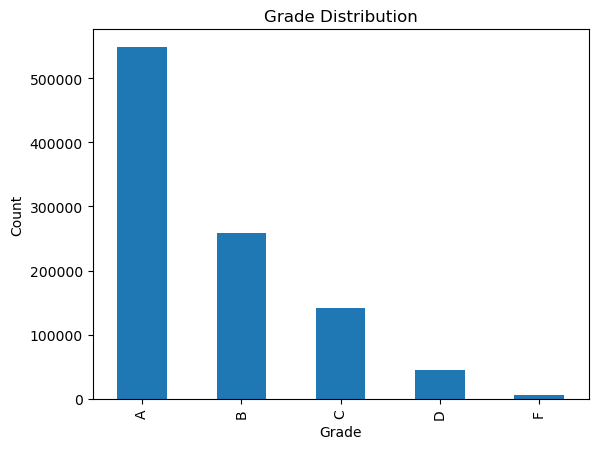

In [7]:
# •	Plot the distribution of grade.
plt.figure()
df['grade'].value_counts().plot(kind='bar')
plt.title("Grade Distribution")
plt.xlabel("Grade")
plt.ylabel("Count")
plt.show()

In [7]:
# •	Create at least two additional visualizations showing the relationship between individual features (weekly_self_study_hours, attendance_percentage, class_participation) and total_score.

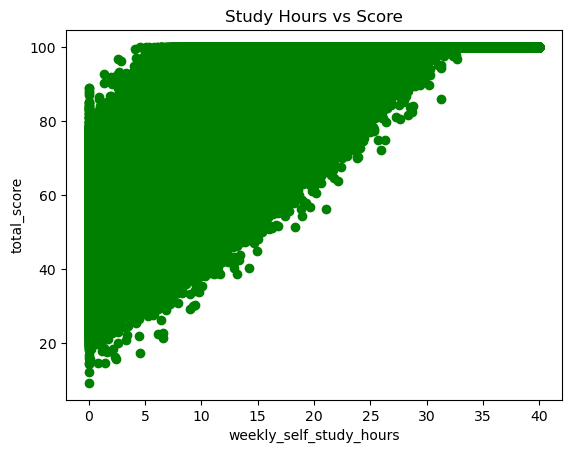

In [8]:
# Feature vs total_score
plt.figure()
plt.scatter(df['weekly_self_study_hours'], df['total_score'],color='green')
plt.xlabel("weekly_self_study_hours")
plt.ylabel("total_score")
plt.title("Study Hours vs Score")
plt.show()


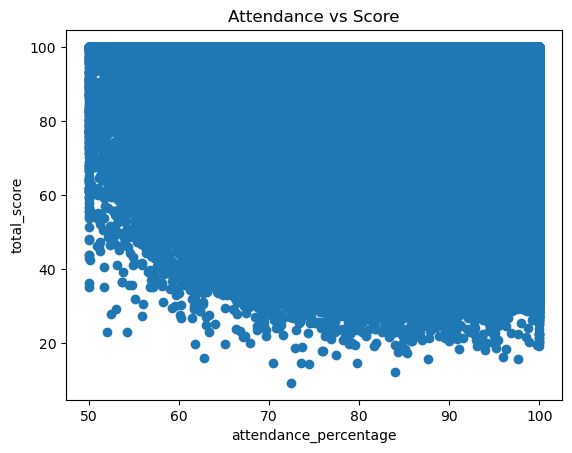

In [9]:
plt.figure()
plt.scatter(df['attendance_percentage'], df['total_score'])
plt.xlabel("attendance_percentage")
plt.ylabel("total_score")
plt.title("Attendance vs Score")
plt.show()



In [ ]:
plt.figure()
plt.scatter(df['class_participation'], df['total_score'], color='red')
plt.xlabel("class_participation")
plt.ylabel("total_score")
plt.title("Participation vs Score")
plt.show()




In [ ]:
# •	Split the data into training and test sets (80/20).

# Features & target
X = df.drop(columns=['total_score','grade'])
y = df['total_score']

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model=RandomForestRegressor()
model.fit(X_train,y_train)
pred=model.predict(X_test)
print(r2_score(y_test,pred))

3. Regression Task — Predict total_score

In [ ]:
# •	Split the data into training and test sets (80/20).

# Features & target
X = df.drop(columns=['total_score','grade'])
y = df['total_score']

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model=RandomForestRegressor()
model.fit(X_train,y_train)
pred=model.predict(X_test)
print(r2_score(y_test,pred))